# 04 · Regression Analysis

**Goal:** estimate the treatment effect within a regression framework, adjust for covariates,
and test whether the effect differs across customers via treatment × covariate interactions.

Because churn is binary, the main model is a **logistic regression**:

`P(y = 1 | t, X) = logit⁻¹(β₀ + β₁·t + γ'X)`

`β₁` is the change in the **log-odds** of churn from contact, holding `X` fixed. Odds ratios are not
intuitive for a business audience, and they are not collapsible: the conditional OR differs from
the population OR even without confounding. The effect is therefore also reported on the
**probability scale** as an *average marginal effect* (AME), and cross-checked with a linear
probability model.

> A regression coefficient is only causal because of the **design**. Here that means randomisation
> within segments, plus adjustment for the variables that drive assignment. The regression itself
> does not create causality.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

from src.functions import (BLUE, GREY, INK_2, ORANGE, OUTCOME, TREATMENT, ate_diff_in_means,
                           collapse_rare, load_data, savefig, set_style)

set_style()
df = load_data()
PROCESSED = ROOT / "data" / "processed"

## 1. Pre-specified covariates

With 160 components and 16 factors, a "kitchen-sink" logit would be unstable (≈ 330 parameters
for 408 events), and choosing covariates by trial and error would invite fishing. The covariate
set is fixed **before** looking at treatment-effect results:

* `PC1`–`PC10`: the ten largest components, which summarise most of the numeric variation.
* `FACTOR4`, `FACTOR6`, `FACTOR18`: the factors that drive treatment assignment (notebook 03),
  which must be adjusted for.
* `FACTOR15`: the factor with the largest churn variation in the EDA, included to improve precision.

Three data issues make an unprocessed logit numerically unstable (non-convergence and
infinite standard errors), so the regression data is prepared as follows:

1. **Outliers:** the PCs are heavy-tailed (`PC1` reaches ~220 SD units). They are winsorised at
   the 0.5th/99.5th percentiles and standardised, so each coefficient is per 1 SD.
2. **Nested factors:** `FACTOR18 = V1` and `FACTOR4 = V1` contain exactly the same 175 customers,
   which makes the design matrix rank-deficient. `FACTOR18 = V1` is pooled into `Other`.
3. **Sparse levels / separation:** levels with fewer than 100 customers or fewer than 5 churners
   are pooled into `Other`. Two `FACTOR15` levels have zero churners, which would push their
   coefficients to −∞.

None of these steps involve the treatment variable.

In [2]:
FACTORS = ["FACTOR4", "FACTOR6", "FACTOR18", "FACTOR15"]
d = df[[OUTCOME, TREATMENT]].copy()
for i in range(1, 11):
    c = f"PC{i}"
    lo, hi = df[c].quantile([0.005, 0.995])
    v = df[c].clip(lo, hi)
    d[c] = (v - v.mean()) / v.std()
for f in FACTORS:
    d[f] = collapse_rare(df[f], min_count=100)
d["FACTOR18"] = d["FACTOR18"].replace({"V1": "Other"})
for f in FACTORS:
    churners = d.groupby(f)[OUTCOME].sum()
    d[f] = d[f].where(~d[f].isin(churners[churners < 5].index), "Other")
pd.DataFrame({"levels": d[FACTORS].nunique(),
              "min churners per level": [d.groupby(f)[OUTCOME].sum().min() for f in FACTORS]})

pcs = " + ".join(f"PC{i}" for i in range(1, 11))
facs = "C(FACTOR4) + C(FACTOR6) + C(FACTOR18) + C(FACTOR15)"
X_terms = f"{pcs} + {facs}"

## 2. Models

1. **Baseline:** `y ~ 1`
2. **Treatment:** `y ~ t`
3. **Treatment + covariates:** `y ~ t + X`
4. **Interactions:** `y ~ t + X + t:(PC1 + PC2 + PC3 + FACTOR18)`

In [3]:
m0 = smf.logit(f"{OUTCOME} ~ 1", d).fit(disp=0)
m1 = smf.logit(f"{OUTCOME} ~ {TREATMENT}", d).fit(disp=0)
m2 = smf.logit(f"{OUTCOME} ~ {TREATMENT} + {X_terms}", d).fit(disp=0, maxiter=200)
inter = f"{TREATMENT}:PC1 + {TREATMENT}:PC2 + {TREATMENT}:PC3 + {TREATMENT}:C(FACTOR18)"
m3 = smf.logit(f"{OUTCOME} ~ {TREATMENT} + {X_terms} + {inter}", d).fit(disp=0, maxiter=200)

def t_row(m, name):
    b, (lo, hi) = m.params[TREATMENT], m.conf_int().loc[TREATMENT]
    return {"model": name, "params": len(m.params), "log-lik": m.llf, "pseudo R²": m.prsquared,
            "AIC": m.aic, "β(t)": b, "OR(t)": np.exp(b), "OR 95% low": np.exp(lo),
            "OR 95% high": np.exp(hi), "p(t)": m.pvalues[TREATMENT]}

summary = pd.DataFrame([
    {"model": "1 · baseline", "params": 1, "log-lik": m0.llf, "pseudo R²": 0.0, "AIC": m0.aic},
    t_row(m1, "2 · treatment"), t_row(m2, "3 · treatment + X"), t_row(m3, "4 · + interactions"),
]).set_index("model")
summary.round(3)

,params,log-lik,pseudo R²,AIC,β(t),OR(t),OR 95% low,OR 95% high,p(t)
model,,,,,,,,,
1 · baseline,1,-1776.980,0.000,3555.959,NaN,NaN,NaN,NaN,NaN
2 · treatment,2,-1776.733,0.000,3557.465,-0.082,0.922,0.735,1.155,0.479
3 · treatment + X,45,-1452.555,0.183,2995.110,-0.127,0.881,0.692,1.121,0.302
4 · + interactions,52,-1450.475,0.184,3004.950,-0.818,0.441,0.117,1.662,0.227


* **Model 2** reproduces the experimental comparison. The odds ratio of 0.92 is the odds version
  of the 3.64% vs 3.36% difference.
* **Model 3:** the covariates explain a meaningful share of churn (pseudo-R² rises and AIC falls),
  but the treatment odds ratio stays close to 1 (0.88, 95% CI 0.69–1.12, p = 0.30). Adjustment
  sharpens the estimate slightly but does not change the conclusion.
* In model 4, the coefficient on `t` is the effect for the *reference* customer (PCs = 0,
  reference level of `FACTOR18`) and should not be read as an average effect.

In [4]:
coef = pd.DataFrame({"coef": m2.params, "OR": np.exp(m2.params),
                     "OR 95% low": np.exp(m2.conf_int()[0]), "OR 95% high": np.exp(m2.conf_int()[1]),
                     "p": m2.pvalues})
coef.loc[[TREATMENT] + [f"PC{i}" for i in range(1, 11)]].round(3)

,coef,OR,OR 95% low,OR 95% high,p
t,-0.127,0.881,0.692,1.121,0.302
PC1,1.058,2.879,2.188,3.790,0.000
PC2,0.187,1.206,0.967,1.503,0.097
PC3,0.483,1.621,1.313,2.003,0.000
PC4,-0.338,0.713,0.616,0.825,0.000
PC5,0.056,1.057,0.941,1.187,0.348
PC6,0.189,1.208,1.065,1.370,0.003
PC7,0.103,1.109,0.959,1.281,0.162
PC8,-0.419,0.658,0.525,0.824,0.000
PC9,-0.099,0.906,0.810,1.013,0.083


Several components are strongly associated with churn. For example, a 1 SD increase in `PC1` is
associated with almost 3× the odds of churning. These are **predictive associations, not causal effects**. The components were
not randomised, and their coefficients absorb everything correlated with them. Only the
coefficient on `t` has a causal interpretation, and only because of the design.

## 3. Effect on the probability scale

In [5]:
ame = m2.get_margeff(at="overall", method="dydx", dummy=True)
ame_t = ame.summary_frame().loc[TREATMENT]

lpm = smf.ols(f"{OUTCOME} ~ {TREATMENT} + {X_terms}", d).fit(cov_type="HC2")
lpm_raw = smf.ols(f"{OUTCOME} ~ {TREATMENT}", d).fit(cov_type="HC2")

reg = pd.DataFrame([
    {"estimator": "Logit AME (t + X)", "ate": ame_t["dy/dx"], "lo": ame_t["Conf. Int. Low"],
     "hi": ame_t["Cont. Int. Hi."], "p": ame_t["Pr(>|z|)"]},
    {"estimator": "LPM, robust SE (t only)", "ate": lpm_raw.params[TREATMENT],
     "lo": lpm_raw.conf_int().loc[TREATMENT, 0], "hi": lpm_raw.conf_int().loc[TREATMENT, 1],
     "p": lpm_raw.pvalues[TREATMENT]},
    {"estimator": "LPM, robust SE (t + X)", "ate": lpm.params[TREATMENT],
     "lo": lpm.conf_int().loc[TREATMENT, 0], "hi": lpm.conf_int().loc[TREATMENT, 1],
     "p": lpm.pvalues[TREATMENT]},
])
(reg.assign(**{c: 100 * reg[c] for c in ["ate", "lo", "hi"]})
    .rename(columns={"ate": "ATE (pp)", "lo": "95% low", "hi": "95% high"})
    .set_index("estimator").round(3))

,ATE (pp),95% low,95% high,p
estimator,,,,
Logit AME (t + X),-0.396,-1.168,0.376,0.315
"LPM, robust SE (t only)",-0.275,-1.053,0.503,0.488
"LPM, robust SE (t + X)",-0.437,-1.211,0.337,0.269


* The **average marginal effect** averages, over all customers, the change in predicted churn
  probability when `t` switches from 0 to 1. It is the regression analogue of the ATE.
* The **linear probability model** with heteroskedasticity-robust (HC2) standard errors estimates
  the risk difference directly. Without covariates it reproduces the difference in means exactly.
  With covariates it is the classic *regression adjustment* estimator for experiments.
* All regression estimates agree with notebook 03: about −0.3 to −0.4 pp, statistically
  indistinguishable from zero. Covariate adjustment narrows the interval only marginally.

## 4. Heterogeneous effects: treatment × covariate interactions

The interaction terms ask whether the effect of contact differs with `PC1`–`PC3` (the main axes
of customer usage) or across `FACTOR18` segments. These four interaction families were chosen in
advance. First, a **joint likelihood-ratio test** of all interactions together, which controls the
false-positive rate across the family:

In [6]:
lr = 2 * (m3.llf - m2.llf)
df_lr = len(m3.params) - len(m2.params)
p_lr = stats.chi2.sf(lr, df_lr)
print(f"LR test, model 4 vs model 3: χ² = {lr:.2f} on {df_lr} df, p = {p_lr:.3f}")

LR test, model 4 vs model 3: χ² = 4.16 on 7 df, p = 0.761


In [7]:
it = [p for p in m3.params.index if p.startswith(f"{TREATMENT}:")]
inter_tab = pd.DataFrame({"coef": m3.params[it], "OR multiplier": np.exp(m3.params[it]),
                          "p": m3.pvalues[it]})
inter_tab["p (Bonferroni)"] = np.minimum(inter_tab["p"] * len(it), 1)
inter_tab.round(3)

,coef,OR multiplier,p,p (Bonferroni)
t:C(FACTOR18)[T.V2],0.389,1.476,0.601,1.0
t:C(FACTOR18)[T.V4],0.600,1.822,0.426,1.0
t:C(FACTOR18)[T.V6],1.024,2.783,0.230,1.0
t:C(FACTOR18)[T.V7],0.948,2.579,0.185,1.0
t:PC1,-0.019,0.982,0.914,1.0
t:PC2,-0.147,0.864,0.420,1.0
t:PC3,0.058,1.060,0.687,1.0


Individual interaction terms are shown for completeness. With several tests, a raw p-value below
0.05 would be expected by chance alone about once in 20 tests, so the Bonferroni-adjusted column
and the joint test above are the ones to rely on.

### Subgroup effects on the probability scale

Interaction coefficients on the log-odds scale are hard to read. A transparent alternative is to
estimate the risk difference **within** each subgroup. `FACTOR18` is one of the variables that
drives assignment, so within its segments the arms are compared directly. Within quartiles of
`PC1`, the arms are IPW-weighted using the propensity from notebook 03.

In [8]:
e = pd.read_parquet(PROCESSED / "propensity.parquet")["propensity"].to_numpy()
w = np.where(df[TREATMENT] == 1, 1 / e, 1 / (1 - e))
t_arr, y_arr = df[TREATMENT].to_numpy(), df[OUTCOME].to_numpy()

def subgroup_effect(mask, weights=None):
    ww = np.ones(mask.sum()) if weights is None else weights[mask]
    tt, yy = t_arr[mask], y_arr[mask]
    p1 = np.average(yy[tt == 1], weights=ww[tt == 1])
    p0 = np.average(yy[tt == 0], weights=ww[tt == 0])
    se = np.sqrt(p1 * (1 - p1) / (tt == 1).sum() + p0 * (1 - p0) / (tt == 0).sum())
    return {"n": int(mask.sum()), "control churners": int(yy[tt == 0].sum()),
            "churn control": p0, "churn treated": p1, "effect": p1 - p0, "se": se}

rows = []
for lvl in d["FACTOR18"].value_counts().index:
    rows.append({"family": "FACTOR18", "subgroup": f"FACTOR18 = {lvl}",
                 **subgroup_effect((d["FACTOR18"] == lvl).to_numpy())})
q = pd.qcut(df["PC1"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
for lvl in q.cat.categories:
    rows.append({"family": "PC1 quartile", "subgroup": f"PC1 {lvl}",
                 **subgroup_effect((q == lvl).to_numpy(), w)})
sub = pd.DataFrame(rows)
sub["lo"], sub["hi"] = sub.effect - 1.96 * sub.se, sub.effect + 1.96 * sub.se

# Cochran's Q test of homogeneity within each family
for fam, g in sub.groupby("family"):
    wts = 1 / g.se**2
    pooled = np.sum(wts * g.effect) / wts.sum()
    Q = np.sum(wts * (g.effect - pooled) ** 2)
    print(f"{fam}: Cochran's Q = {Q:.2f} on {len(g) - 1} df, p = {stats.chi2.sf(Q, len(g) - 1):.2f}")
sub.assign(**{c: 100 * sub[c] for c in ["churn control", "churn treated", "effect", "lo", "hi"]}).round(2)

FACTOR18: Cochran's Q = 2.80 on 4 df, p = 0.59
PC1 quartile: Cochran's Q = 4.79 on 3 df, p = 0.19


,family,subgroup,n,control churners,churn control,churn treated,effect,se,lo,hi
0,FACTOR18,FACTOR18 = V7,5388,31,3.36,3.45,0.09,0.01,-1.19,1.37
1,FACTOR18,FACTOR18 = V4,3375,38,3.93,3.57,-0.36,0.01,-1.80,1.07
2,FACTOR18,FACTOR18 = V2,2300,25,3.49,2.59,-0.90,0.01,-2.46,0.65
3,FACTOR18,FACTOR18 = V6,526,6,3.19,4.73,1.54,0.02,-1.84,4.92
4,FACTOR18,FACTOR18 = Other,307,5,5.32,2.82,-2.50,0.03,-7.55,2.55
5,PC1 quartile,PC1 Q1 (lowest),2974,31,3.40,3.08,-0.32,0.01,-1.75,1.10
6,PC1 quartile,PC1 Q2,2974,16,1.93,3.08,1.14,0.01,-0.08,2.37
7,PC1 quartile,PC1 Q3,2974,26,3.66,2.79,-0.87,0.01,-2.45,0.71
8,PC1 quartile,PC1 Q4 (highest),2974,32,4.95,4.59,-0.37,0.01,-2.25,1.52


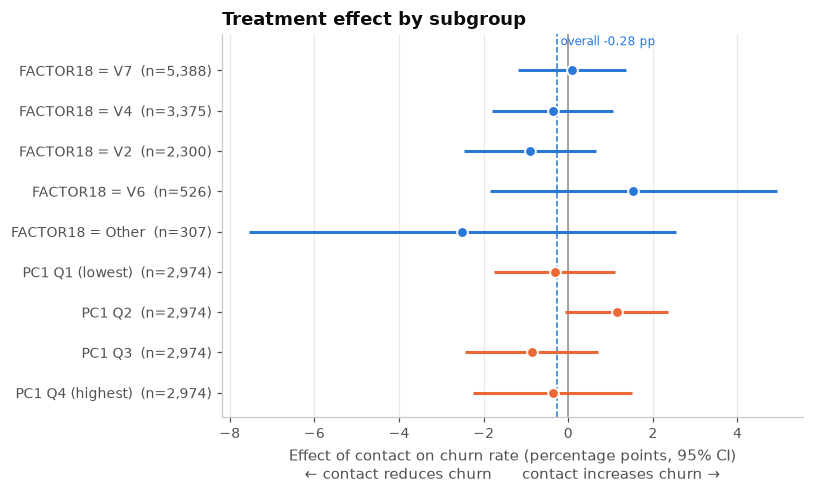

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
overall = ate_diff_in_means(y_arr, t_arr)
order = sub.iloc[::-1].reset_index(drop=True)
ypos = np.arange(len(order))
ax.axvline(0, color=GREY, linewidth=1)
ax.axvline(100 * overall["ate"], color=BLUE, linewidth=1, linestyle="--")
for i, row in order.iterrows():
    colour = BLUE if row.family == "FACTOR18" else ORANGE
    ax.errorbar(100 * row.effect, i, xerr=[[100 * (row.effect - row.lo)], [100 * (row.hi - row.effect)]],
                fmt="o", color=colour, markersize=7, elinewidth=2, capsize=0,
                markeredgecolor="white", markeredgewidth=1.2)
ax.set_yticks(ypos, [f"{s}  (n={n:,})" for s, n in zip(order.subgroup, order.n)])
ax.set_xlabel("Effect of contact on churn rate (percentage points, 95% CI)\n← contact reduces churn      contact increases churn →")
ax.set_title("Treatment effect by subgroup")
ax.text(100 * overall["ate"], len(order) - 0.45, f" overall {100 * overall['ate']:+.2f} pp",
        fontsize=8, color=BLUE, va="bottom")
ax.set_ylim(-0.6, len(order) - 0.1)
ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig(fig, "fig5_subgroup_effects")

**Reading the figure.** Each row estimates the effect of contact within one subgroup, using only
customers in that subgroup. Blue rows are `FACTOR18` segments and orange rows are quartiles of the
main usage component `PC1`. Point estimates vary from clearly negative to positive. The confidence
intervals are wide, however, and nearly all overlap each other and the overall estimate. The
homogeneity tests (Cochran's Q, p = 0.59 and 0.19) confirm that this spread is consistent with
sampling noise. Small subgroups (e.g. `FACTOR18 = Other`: 307 customers, only 5 control churners)
produce the most extreme and least reliable estimates. This is the classic pattern of noise masquerading as heterogeneity.

## 5. All ATE estimates side by side

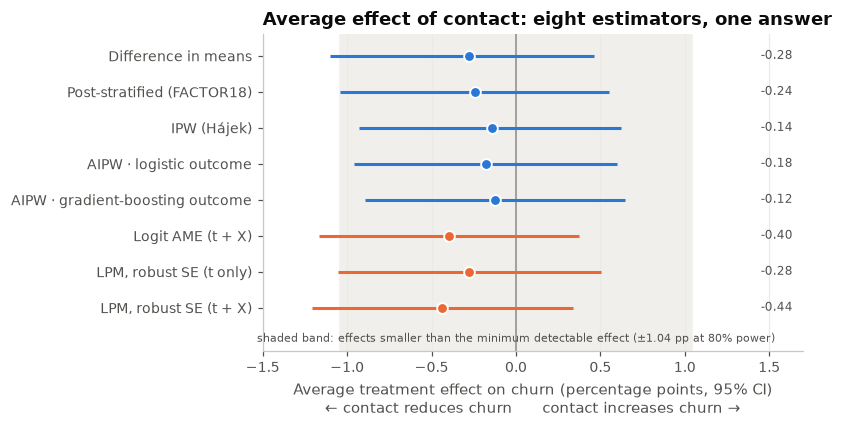

In [10]:
exp_est = pd.read_csv(PROCESSED / "ate_estimates_experimental.csv")
all_est = pd.concat([exp_est.assign(source="Experimental (nb 03)"),
                     reg.assign(source="Regression (nb 04)")], ignore_index=True)
all_est.to_csv(PROCESSED / "ate_estimates_all.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
order = all_est.iloc[::-1].reset_index(drop=True)
ypos = np.arange(len(order))
ax.axvspan(-1.04, 1.04, color="#f0efec", zorder=0)
ax.axvline(0, color=GREY, linewidth=1)
for i, row in order.iterrows():
    colour = BLUE if row.source.startswith("Experimental") else ORANGE
    ax.errorbar(100 * row.ate, i, xerr=[[100 * (row.ate - row.lo)], [100 * (row.hi - row.ate)]],
                fmt="o", color=colour, markersize=7, elinewidth=2, capsize=0,
                markeredgecolor="white", markeredgewidth=1.2)
    ax.text(1.45, i, f"{100 * row.ate:+.2f}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(ypos, order.estimator)
ax.set_xlim(-1.5, 1.7)
ax.set_xlabel("Average treatment effect on churn (percentage points, 95% CI)\n← contact reduces churn      contact increases churn →")
ax.set_title("Average effect of contact: eight estimators, one answer")
ax.text(0, -0.95, "shaded band: effects smaller than the minimum detectable effect (±1.04 pp at 80% power)",
        ha="center", fontsize=7.5, color=INK_2)
ax.set_ylim(-1.2, len(order) - 0.4)
ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig(fig, "fig4_ate_estimates")

**Reading the figure.** Blue rows are design-based estimators (notebook 03) and orange rows are
regression estimators. All eight point estimates are small and negative, and every 95% interval
crosses zero. The shaded band marks the range of effects smaller than the experiment's minimum
detectable effect. The whole cluster of point estimates sits well inside it, which is why no
estimator reaches significance.

## Summary and limitations

* Logistic regression, its average marginal effect and the robust linear probability model all
  agree with the experimental analysis: **no statistically detectable average effect**, point
  estimates around −0.3 to −0.4 pp.
* **Interactions:** the pre-specified treatment × covariate interactions are not jointly
  significant (LR test p = 0.76; no term survives Bonferroni correction), and subgroup effects are
  consistent with a common effect. Within this regression
  framework there is no reliable evidence that the effect differs across customers.
* **Limitations:** (i) the logit assumes effects are linear in the log-odds of the included
  covariates, so heterogeneity along other directions is not tested here (notebook 05 relaxes this
  with machine learning); (ii) only a handful of interactions were tested, by design; (iii) the
  covariates are anonymised, so even a significant interaction could not be explained in business
  terms; (iv) the causal reading of `β(t)` depends on assignment being random within the segments
  adjusted for.